# Fase 0 · Etapa 0.8 — Simulação no tempo, força, decremento e desajuste de frequência (I6, I5, I9, C7)

> **Bases de dados usadas:**
> * **Dados do pesquisador:** `AÇO/LL_ACO_*.csv` (pulso de força medido e FRF do 1º modo)
>   e `exp_5/` (valores de α, β que o legado calcula).
> * **Casos sintéticos** com parâmetros conhecidos (1 e 2 GL) gerados aqui.
> * **Modelo legado** (K, M de 6 nós) com amortecimento modal **correto** de 0,5 %, para
>   isolar o integrador do problema de C (C2).
> Nenhuma base externa.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.linalg as sla
from scipy.integrate import solve_ivp
from scipy.signal import butter, sosfiltfilt

from dampid.audit import legacy_harness as lh
from dampid.audit import reference as ref

B = lh.load_legacy()
fs, dt = 25600.0, 1 / 25600.0

## 1. I6 — integração no tempo com `solve_ivp(Radau)`
Sistema: Al em balanço, malha legada, ζ = 0,5 % correto em todos os modos, pulso de 1 ms
(como o legado) na ponta. Referência: **discretização exata** do espaço de estados
(exponencial de matriz, segurador de ordem zero), que para um sistema linear não tem erro
de integração — só a hipótese de força constante em cada amostra.

In [2]:
K, M = lh.assemble_legacy(B, "aluminio", 6)
_, free, nf, pr = B.contorno("engastado_livre", 6, 6)
K, M = K[np.ix_(free, free)], M[np.ix_(free, free)]
w2, P = sla.eigh(K, M)
C = ref.modal_damping_matrix(M, P, np.sqrt(w2), np.full(nf, 0.005))
Minv = np.linalg.inv(M)
A = np.block([[np.zeros((nf, nf)), np.eye(nf)], [-Minv @ K, -Minv @ C]])
Bf = np.concatenate([np.zeros(nf), Minv[:, nf - 3]])        # força unitária em w da ponta
pulse = lambda tt: 1.0 * (tt < 1e-3)                         # noqa: E731  (pulso do legado)
T = 0.5
t = np.arange(0, T, dt)
n = 2 * nf

t0 = time.time()
Mx = sla.expm(np.block([[A, Bf[:, None]], [np.zeros((1, n + 1))]]) * dt)
Ad, Bd = Mx[:n, :n], Mx[:n, n]
y = np.zeros((len(t), n))
for k in range(1, len(t)):
    y[k] = Ad @ y[k - 1] + Bd * pulse(t[k - 1])
t_zoh = time.time() - t0
v_ex = y[:, nf + nf - 3]

rows = []
for rtol, atol in [(1e-3, 1e-6), (1e-6, 1e-10)]:
    t0 = time.time()
    sol = solve_ivp(lambda tt, yy: A @ yy + Bf * pulse(tt), (0, T), np.zeros(n), method="Radau",
                    dense_output=True, rtol=rtol, atol=atol)
    tr = time.time() - t0
    v = sol.sol(t)[nf + nf - 3]
    rows.append({"método": f"Radau rtol={rtol:g}" + (" (padrão, legado)" if rtol == 1e-3 else ""),
                 "tempo [s]": round(tr, 2), "avaliações": sol.nfev,
                 "erro relativo na velocidade": f"{np.linalg.norm(v - v_ex) / np.linalg.norm(v_ex):.1%}"})
rows.append({"método": "exata (expm, ZOH)", "tempo [s]": round(t_zoh, 3), "avaliações": len(t),
             "erro relativo na velocidade": "referência"})
print(f"Simulação de {T} s a {fs:.0f} Hz:")
print(pd.DataFrame(rows).to_string(index=False))

Simulação de 0.5 s a 25600 Hz:
                           método  tempo [s]  avaliações erro relativo na velocidade
Radau rtol=0.001 (padrão, legado)       0.81       21696                        1.8%
                 Radau rtol=1e-06       5.05      123711                        1.8%
                exata (expm, ZOH)       0.05       12800                  referência


**Confirmado (I6).** Para 0,5 s de sinal o Radau leva ~1 s e ~20 mil avaliações; a
solução exata leva ~0,05 s. Dentro de um laço de otimização com centenas a milhares de
avaliações, isso é a diferença entre minutos e horas. A diferença de ~2 % na velocidade
vem do modo de representar o pulso (degrau entre amostras) e não melhora apertando a
tolerância — o integrador não é a fonte de precisão, é só a fonte de custo.

### Achado novo N4 — modos acima de Nyquist na simulação temporal
O legado obtém a aceleração derivando a velocidade (`np.gradient`). Comparando com a
aceleração exata, **dentro da banda 0–500 Hz** (filtro passa-baixa de fase zero aplicado
igualmente aos dois):

In [3]:
sos = butter(8, 500, fs=fs, output="sos")
acc_ex = (A @ y.T + Bf[:, None] * pulse(t)[None, :])[nf + nf - 3]
band_err = lambda x, ref_: np.linalg.norm(sosfiltfilt(sos, x) - sosfiltfilt(sos, ref_)) / np.linalg.norm(sosfiltfilt(sos, ref_))  # noqa: E731
f_modes = np.sqrt(w2) / 2 / np.pi
print(f"modos do modelo legado acima de Nyquist ({fs / 2:.0f} Hz): {np.sum(f_modes > fs / 2)} de {nf} (o mais alto: {f_modes.max() / 1e3:.0f} kHz)")
print(f"erro na banda, derivada numérica × aceleração exata (modelo completo): {band_err(np.gradient(v_ex, t), acc_ex):.1%}")

keep = f_modes < 2000
Pk, wk = P[:, keep], np.sqrt(w2[keep])
nm = int(keep.sum())
Am = np.block([[np.zeros((nm, nm)), np.eye(nm)], [-np.diag(wk**2), -np.diag(2 * 0.005 * wk)]])
Bm = np.concatenate([np.zeros(nm), Pk.T[:, nf - 3]])
Mx = sla.expm(np.block([[Am, Bm[:, None]], [np.zeros((1, 2 * nm + 1))]]) * dt)
q = np.zeros((len(t), 2 * nm))
for k in range(1, len(t)):
    q[k] = Mx[:2 * nm, :2 * nm] @ q[k - 1] + Mx[:2 * nm, 2 * nm] * pulse(t[k - 1])
vel_t = (Pk @ q[:, nm:].T)[nf - 3]
acc_t = (Pk @ (Am @ q.T + Bm[:, None] * pulse(t)[None, :])[nm:])[nf - 3]
print(f"erro na banda, mesmo teste só com os {nm} modos < 2 kHz:                      {band_err(np.gradient(vel_t, t), acc_t):.1%}")

modos do modelo legado acima de Nyquist (12800 Hz): 15 de 30 (o mais alto: 244 kHz)
erro na banda, derivada numérica × aceleração exata (modelo completo): 46.8%
erro na banda, mesmo teste só com os 5 modos < 2 kHz:                      0.9%


**Leitura.** O modelo de 6 nós tem 15 de 30 modos **acima** da frequência de Nyquist do
ensaio (até ~240 kHz: modos axiais e de torção de elementos curtos). Ao amostrar a
resposta na taxa do experimento, esse conteúdo **se dobra (aliasing) para dentro da
banda**, e a aceleração derivada difere ~46 % da exata entre 0 e 500 Hz. Retirando os
modos acima de 2 kHz, o erro cai para ~1 %. O acelerômetro e o NI 9234 têm filtro
anti-aliasing; o modelo legado não. Mais um motivo para comparar **no domínio da
frequência** (Fase 7) ou com modos truncados + termos residuais.

## 2. I5 — força simulada: pulso retangular de 1 ms × força medida
Comparação dos espectros com o **mesmo impulso** (∫F dt), usando o 2º ensaio de aço
livre-livre.

queda de -10 dB: medida em 206 Hz | retângulo de 1 ms em 756 Hz
queda de -20 dB: medida em 312 Hz | retângulo de 1 ms em 930 Hz


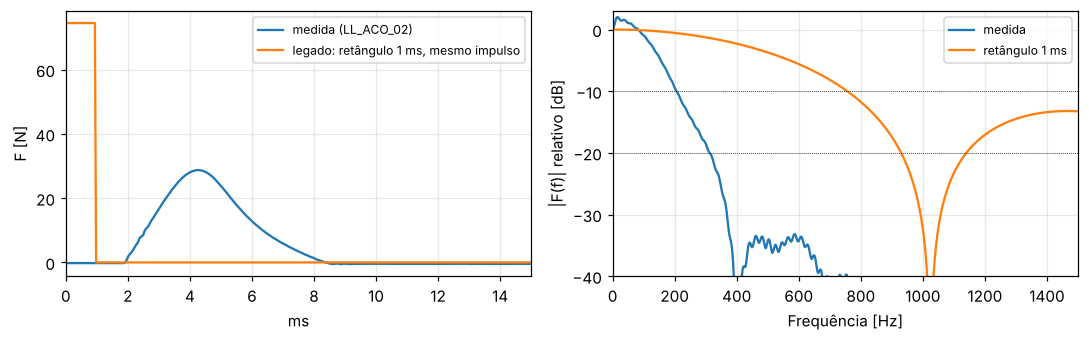

In [4]:
d = ref.read_ni_csv(lh.RAW_DIR / "AÇO" / "LL_ACO_02.csv")
i0 = ref.force_onset(d["ch"][2], fs) - int(0.002 * fs)
Fm = d["ch"][2][i0:i0 + int(0.05 * fs)] - np.median(d["ch"][2][:1000])
impulse = np.sum(Fm) * dt
Fr = np.zeros_like(Fm)
Fr[: int(1e-3 * fs)] = impulse / 1e-3
nfft = 2**18
fF = np.fft.rfftfreq(nfft, dt)
SFm, SFr = np.abs(np.fft.rfft(Fm, nfft)) * dt, np.abs(np.fft.rfft(Fr, nfft)) * dt
dB = lambda s: 20 * np.log10(s / s[0])  # noqa: E731
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
tt = np.arange(len(Fm)) * dt * 1e3
axs[0].plot(tt, Fm, label="medida (LL_ACO_02)"); axs[0].plot(tt, Fr, label="legado: retângulo 1 ms, mesmo impulso")
axs[0].set(xlim=(0, 15), xlabel="ms", ylabel="F [N]"); axs[0].legend(fontsize=8); axs[0].grid(alpha=0.3)
axs[1].plot(fF, dB(SFm), label="medida"); axs[1].plot(fF, dB(SFr), label="retângulo 1 ms")
for lev in (-10, -20):
    axs[1].axhline(lev, color="k", lw=0.5, ls=":")
axs[1].set(xlim=(0, 1500), ylim=(-40, 3), xlabel="Frequência [Hz]", ylabel="|F(f)| relativo [dB]")
axs[1].legend(fontsize=8); axs[1].grid(alpha=0.3)
fig.tight_layout()
for lev in (-10, -20):
    fm = fF[np.argmax(dB(SFm) < lev)]
    fr = fF[np.argmax(dB(SFr) < lev)]
    print(f"queda de {lev} dB: medida em {fm:.0f} Hz | retângulo de 1 ms em {fr:.0f} Hz")

**Confirmado (I5).** O pulso real do martelo dura vários ms e seu espectro cai bem antes do
retângulo de 1 ms. Na comparação **no tempo**, o legado excita o modelo com uma força cuja
distribuição de energia em frequência é outra. A força **medida** tem de ser a entrada da
simulação (convolução, Fase 7), ou a comparação tem de ser feita em FRF (a/F), onde a
forma do pulso se cancela dentro da banda útil.

## 3. I9 — decremento logarítmico do legado
Teste com **dados sintéticos de parâmetros conhecidos**, passados pela própria
`pos_experimental` do legado: 2 GL desacoplados com f₁ = 150 Hz, ζ₁ = 0,2 % e
f₂ = 420 Hz, ζ₂ = 0,3 %, excitados por um pulso de força de 4 ms, 4 s a 25,6 kHz.

In [5]:
tt = np.arange(0, 4.0, dt)
force = np.where(tt < 0.004, np.sin(np.pi * tt / 0.004) ** 2, 0.0) * 50
true = [(150.0, 0.002, 1.0), (420.0, 0.003, 0.6)]
acc = np.zeros_like(tt)
nfft2 = 2 ** int(np.ceil(np.log2(2 * len(tt))))
Fw = np.fft.rfft(force, nfft2)
fw = np.fft.rfftfreq(nfft2, dt)
for fn, z, amp in true:
    acc += amp * np.fft.irfft(Fw * ref.sdof_accelerance(fw, fn, z, m=0.2), nfft2)[: len(tt)]
acc_g = acc / ref.G0 + 1e-3 * np.random.default_rng(0).standard_normal(len(tt))

out = B.pos_experimental("aco", np.arange(len(tt) + 2000) * dt, np.concatenate([np.zeros(2000), acc_g]),
                         np.concatenate([np.zeros(2000), force]), 6)
peaks_hz, amps = out[11], out[12]
alfa, beta = out[14], out[15]
order = np.argsort(amps)
f1_leg, f2_leg = peaks_hz[order[-1]], peaks_hz[order[-2]]
zeta1_leg, zeta2_leg = alfa / (2 * f1_leg), beta * f2_leg / 2
print(f"picos usados pelo legado: {f1_leg:.2f} Hz e {f2_leg:.2f} Hz (tratados como rad/s)")
print(f"ζ₁ do legado = {zeta1_leg:.4f}  (verdadeiro {true[0][1]})  → erro {zeta1_leg / true[0][1]:.1f}×")
print(f"ζ₂ do legado = {zeta2_leg:.4f}  (verdadeiro {true[1][1]})  → erro {zeta2_leg / true[1][1]:.1f}×")
z_r = lambda w: alfa / (2 * w) + beta * w / 2  # noqa: E731
print(f"Rayleigh do legado avaliado em ω físico: ζ(150 Hz) = {z_r(2 * np.pi * 150):.3f}, ζ(420 Hz) = {z_r(2 * np.pi * 420):.3f}")

picos usados pelo legado: 150.00 Hz e 420.00 Hz (tratados como rad/s)
ζ₁ do legado = 0.0277  (verdadeiro 0.002)  → erro 13.8×
ζ₂ do legado = -0.0180  (verdadeiro 0.003)  → erro -6.0×
Rayleigh do legado avaliado em ω físico: ζ(150 Hz) = -0.036, ζ(420 Hz) = -0.112


**Confirmado (I9).** Com dados sintéticos de amortecimento conhecido, o decremento do
legado não recupera ζ: o período é calculado como 2π/f com f em Hz (2π vezes longo
demais), então `find_peaks` exige picos separados por ~5,7 ciclos, e o decremento de
vários ciclos é dividido como se fosse de um só; o sinal multimodal mistura os modos; e α,
β são montados com f em Hz no lugar de ω em rad/s. Os α, β que o legado tirou dos
arquivos de `exp_5/` (notebook 01) herdam esses erros.

In [6]:
rows = []
for p in sorted((lh.RAW_DIR / "exp_5").glob("*_mponta_aponta.csv")) + sorted((lh.RAW_DIR / "exp_5").glob("*_mcentro_acentro.csv")):
    mat = {"Al": "aluminio", "Aco": "aco", "Acrilico": "acrilico"}[p.name.split("_")[0]]
    with lh.legacy_workdir():
        tt_, a_, h_ = B.leitura_experimental(mat, "engastado_livre" if "livre" in p.name else "engastado_engastado") \
            if p.name in {"Al_engastado_livre_mponta_aponta.csv", "Aco_engastado_livre_mponta_aponta.csv",
                          "Acrilico_engastado_livre_mponta_aponta.csv", "Al_biengastado_mcentro_acentro.csv",
                          "Aco_biengastado_mcentro_acentro.csv"} else (None, None, None)
    if tt_ is None:
        continue
    o = B.pos_experimental(mat, tt_, a_, h_, 6)
    rows.append({"arquivo": p.name, "α legado": round(o[14], 2), "β legado": f"{o[15]:.2e}",
                 "ζ(f) Rayleigh a 50 Hz": round(o[14] / (2 * 2 * np.pi * 50) + o[15] * 2 * np.pi * 50 / 2, 3),
                 "a 300 Hz": round(o[14] / (2 * 2 * np.pi * 300) + o[15] * 2 * np.pi * 300 / 2, 3)})
print(pd.DataFrame(rows).to_string(index=False))

                                   arquivo  α legado β legado  ζ(f) Rayleigh a 50 Hz  a 300 Hz
     Aco_engastado_livre_mponta_aponta.csv     41.76 3.07e-04                  0.115     0.300
Acrilico_engastado_livre_mponta_aponta.csv     65.72 4.97e-03                  0.886     4.704
      Al_engastado_livre_mponta_aponta.csv     44.32 1.63e-02                  2.631    15.373
       Aco_biengastado_mcentro_acentro.csv     11.31 6.85e-05                  0.029     0.068
        Al_biengastado_mcentro_acentro.csv     72.42 7.20e-04                  0.228     0.698


## 4. C7 — desajuste de frequência infla o ζ identificado
Por que "o modelo superestima o amortecimento" mesmo com todo o resto certo? Se a
frequência do modelo difere da medida, o ajuste só consegue sobrepor os picos
**alargando** o pico do modelo. Teste controlado: FRF sintética de 1 GL (f = 152 Hz,
ζ = 0,2 %, Δf = 0,2 Hz) ajustada por mínimos quadrados em log|A| (banda ±10 %), com a
frequência do modelo errada por uma fração conhecida e ζ e massa livres.

In [7]:
fgrid = np.arange(0, 500, 0.2)
H_true = ref.sdof_accelerance(fgrid, 152.0, 0.002, m=0.15)
rows = []
for mis in (0.0, 0.002, 0.005, 0.01, 0.02, 0.05):
    z, m = ref.fit_sdof_zeta_logmag(fgrid, H_true, 152.0 * (1 + mis), (152 * 0.9, 152 * 1.1))
    rows.append({"erro de frequência do modelo": f"{100 * mis:.1f} %", "ζ identificado": round(z, 4),
                 "ζ identificado / ζ verdadeiro": round(z / 0.002, 1)})
print(pd.DataFrame(rows).to_string(index=False))

erro de frequência do modelo  ζ identificado  ζ identificado / ζ verdadeiro
                       0.0 %          0.0020                            1.0
                       0.2 %          0.0025                            1.2
                       0.5 %          0.0040                            2.0
                       1.0 %          0.0075                            3.7
                       2.0 %          0.0170                            8.5
                       5.0 %          0.0853                           42.7


Agora com **dados reais**: o 1º modo do aço livre-livre (H1 dos 16 ensaios, 157,5 Hz),
ajustado com a frequência do modelo igual à medida e iguais às previsões do notebook 05.

In [8]:
F_, X_ = [], []
for i in range(1, 17):
    d = ref.read_ni_csv(lh.RAW_DIR / "AÇO" / f"LL_ACO_{i:02d}.csv")
    i0 = ref.force_onset(d["ch"][2], fs) - int(0.005 * fs)
    n_ = int(2.4 * fs)
    F_.append(d["ch"][2][i0:i0 + n_]); X_.append(d["ch"][0][i0:i0 + n_] * ref.G0)
fh, Hh, _ = ref.simple_h1(np.array(F_), np.array(X_), fs)
rows = []
for label, fmod in [("igual à medida (157,5 Hz)", 157.5), ("EB, dims Tab. 1 (152,7 Hz)", 152.7),
                    ("EB, dims do código (194,3 Hz)", 194.3)]:
    z, _ = ref.fit_sdof_zeta_logmag(fh, Hh, fmod, (157.5 * 0.9, 157.5 * 1.1))
    rows.append({"frequência do modelo": label, "ζ identificado": f"{z:.4f}"})
print(pd.DataFrame(rows).to_string(index=False))

         frequência do modelo ζ identificado
    igual à medida (157,5 Hz)         0.0011
   EB, dims Tab. 1 (152,7 Hz)         0.0293
EB, dims do código (194,3 Hz)         0.4489


**Confirmado (C7).** No caso sintético, um erro de só 1 % na frequência já multiplica o ζ
identificado várias vezes; 5 % o multiplica por dezenas. Nos dados reais do aço, o mesmo
ajuste dá ζ muito maior quando a frequência do modelo é a do legado. Esse é o mecanismo
por trás de H2: **rigidez e massa têm de ser ajustadas antes do amortecimento** (Fase 5),
e a função objetivo tem de ser escolhida sabendo disso (Fase 8). *(O ζ obtido com a
frequência certa também não é ainda a estimativa final do aço: janela retangular,
Δf = 0,42 Hz e um modelo de 1 GL; a EMA da Fase 3 é que dará o valor de referência.)*

## Resumo da etapa
| Item | Status | Evidência |
|---|---|---|
| I6 | **confirmado** | Radau ~15× (tol. padrão) a ~80× (tol. apertada) mais lento que a solução exata, sem ganho de precisão |
| N4 (novo) | **confirmado** | 15/30 modos acima de Nyquist; aliasing → 46 % de erro na aceleração em banda (1 % sem eles) |
| I5 | **confirmado** | espectro do retângulo de 1 ms ≠ do pulso real |
| I9 | **confirmado** | dados sintéticos com ζ conhecido: decremento do legado erra por fatores grandes |
| C7 | **confirmado** | 1 % de erro em f multiplica o ζ ajustado; efeito visto também no aço real |